# Prétraitement + entraînement (v3) – IRM cérébrales `yes` / `no`

Version **corrigée et prolongée** de votre notebook `Pretraitement_images_1.ipynb`. L'ordre des étapes a changé : le contrôle des métadonnées est maintenant fait **après** le regroupement des quasi-doublons.

## Journal des corrections

| # | Où (votre notebook) | Ce qui ne collait pas | Correction dans cette version |
|---|---|---|---|
| 1 | Section « Les métadonnées permettent-elles de deviner la classe ? » | La validation croisée n'était **pas groupée** et se faisait **avant** le regroupement des quasi-doublons. Les copies d'une même image (mêmes dimensions, même poids) se retrouvaient dans l'entraînement et le test de la forêt aléatoire : les **93,7 %** étaient gonflés | Contrôle déplacé **après** les groupes, validation croisée **par groupes**, et score détaillé **variable par variable** |
| 2 | Paramètre `HAMMING_MAX = 10` (quasi-doublons et séparation) | L'histogramme montre une queue de variantes jusqu'à ≈ 30 bits ; les distances minimales train↔val/test valaient seulement 11 et 12 : des variantes d'une même image pouvaient encore passer d'un ensemble à l'autre | Seuil **choisi automatiquement** (plafond 30, sans groupe démesuré) à partir d'un **tableau de balayage**, **diagnostic de fuite résiduelle** après la séparation |
| 3 | Section « Prétraitement des images » | Ni la luminosité du fond (certains fonds sont gris), ni la netteté (images agrandies de façon très différente) n'étaient neutralisées | **Normalisation d'intensité**, **égalisation de résolution**, flou aléatoire dans l'augmentation, et **sonde de raccourcis sur les pixels** |
| 4 | Cellule d'écriture des images prétraitées | Votre correction (nouveau dossier au lieu de `rmtree`) est conservée. Elle changeait `PREP_DIR` sans le mémoriser | Le chemin du dossier est enregistré dans `stats.json` |
| 5 | Cellule d'entraînement | Seule la dernière couche était entraînée (backbone entièrement gelé), taux d'apprentissage constant | **Deux étapes** : tête seule, puis fine-tuning des derniers blocs avec planification cosinus |
| 6 | Cellules d'entraînement et d'évaluation : seuil | Seuil figé à 0,5 | Seuil **choisi sur la validation** (rappel ≥ 95 %), jamais sur le test |
| 7 | Cellule d'évaluation finale | Aucune mesure d'incertitude, aucune analyse d'erreurs | **Intervalles de confiance par groupes**, matrice de confusion, erreurs, **Grad-CAM** |
| 8 | (nouveau) | — | Sauvegarde du modèle, `model_card.json` et fonction `predict_image()` |

Les images d'origine ne sont **jamais modifiées**. À lancer avec *Restart & Run All* dans le dossier qui contient `yes/` et `no/`.

In [1]:
from pathlib import Path
import hashlib, json, random, shutil, tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score

# ----------------------------- paramètres -----------------------------
DATA_DIR = Path(".")                 # dossier contenant yes/ et no/
PREP_DIR = Path("data_prepared")     # dossier de sortie (un nouveau dossier est créé si celui-ci existe déjà)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
CLASS_NAMES = {"yes", "no"}

SEED = 42
IMG_SIZE = 224                       # taille d'entrée du réseau (224 pour EfficientNet-B0)
HASH_SIZE = 16                       # dHash de 16 x 16 = 256 bits
HAMMING_MAX = None                   # distance max (sur 256 bits) dans un groupe ; None = choisi automatiquement (voir section 3)
HAMMING_CAP = 30                     # plafond du seuil automatique (les variantes de l'EDA vont jusqu'à ≈ 30 bits)
MAX_GROUP_FRACTION = 0.03            # un groupe ne doit pas dépasser 3 % du jeu (sinon : regroupement en chaîne)

USE_CROP = True                      # recadrer les bords noirs autour du cerveau
NORMALIZE_INTENSITY = True           # même échelle de gris et même noir de fond pour toutes les images
EQUALIZE_RESOLUTION = True           # même niveau de détail pour toutes les images (évite le raccourci « netteté »)
COMMON_RES = 160                     # côté max (px) auquel on ramène les images avant l'agrandissement final
USE_IMAGENET_STATS = True            # True si modèle pré-entraîné (EfficientNet...)

random.seed(SEED); np.random.seed(SEED)

## 1. Inventaire des images et métadonnées

In [2]:
def is_candidate(p):
    return (
        p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
        and not any(part == PREP_DIR.name or part.startswith(f"{PREP_DIR.name}_") for part in p.parts)
        and any(parent.name.lower() in CLASS_NAMES for parent in p.parents)
    )

paths = sorted(p for p in DATA_DIR.rglob("*") if is_candidate(p))
if not paths:
    raise ValueError(f"Aucune image trouvée dans {DATA_DIR.resolve()}. Vérifie DATA_DIR et les dossiers yes/ no/.")

records, removed = [], []          # removed = journal de tout ce qui est écarté
for p in paths:
    try:
        with Image.open(p) as im:
            im.load()
            records.append({
                "path": str(p),
                "label": next(par.name.lower() for par in p.parents if par.name.lower() in CLASS_NAMES),
                "format": im.format,
                "width": im.width,
                "height": im.height,
                "channels": len(im.getbands()),
                "size_kb": p.stat().st_size / 1024,
            })
    except (UnidentifiedImageError, OSError, ValueError) as error:
        removed.append((str(p), f"illisible : {error}"))

df = pd.DataFrame(records)
print(f"Images lues : {len(df)} | illisibles : {len(removed)} | dossier : {DATA_DIR.resolve()}")
display(df["label"].value_counts().to_frame("nombre_images"))
display(df.groupby("label")[["width", "height", "channels", "size_kb"]].agg(["min", "median", "max"]).round(1))

Images lues : 2999 | illisibles : 0 | dossier : C:\Users\Mahamadou\Documents\DL\Tumeur


,nombre_images
label,
yes,1500
no,1499


width              height              channels            size_kb  \
        min median   max    min median   max      min median max     min   
label                                                                      
no      150  227.0  1920    168  238.0  1080        1    3.0   4     3.4   
yes     175  283.0  1275    167  342.0  1427        1    3.0   3     4.7   

                     
      median    max  
label                
no      10.8  710.8  
yes     19.6  298.0

## 2. Doublons exacts (SHA-256)

Une image présente dans `yes` **et** dans `no` est retirée (étiquette contradictoire) ; pour les autres doublons exacts, une seule copie est gardée. Tout est consigné dans `removed_images.csv`.

In [3]:
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

df["sha256"] = df["path"].map(sha256_file)

labels_per_hash = df.groupby("sha256")["label"].nunique()
conflict_mask = df["sha256"].isin(labels_per_hash[labels_per_hash > 1].index)
removed += [(p, "même image dans yes et no") for p in df.loc[conflict_mask, "path"]]
df = df[~conflict_mask]

dup_mask = df.duplicated("sha256", keep="first")
removed += [(p, "doublon exact") for p in df.loc[dup_mask, "path"]]
df = df[~dup_mask].drop(columns="sha256").reset_index(drop=True)

pd.DataFrame(removed, columns=["path", "raison"]).to_csv("removed_images.csv", index=False)
print(f"Conflits d'étiquette retirés : {int(conflict_mask.sum())}")
print(f"Doublons exacts retirés      : {int(dup_mask.sum())}")
print(f"Images restantes             : {len(df)}  (journal : removed_images.csv)")

Conflits d'étiquette retirés : 0
Doublons exacts retirés      : 1
Images restantes             : 2998  (journal : removed_images.csv)


## 3. Quasi-doublons (dHash 256 bits, retournements inclus)

Chaque image reçoit une empreinte de 256 bits ; on compare aussi chaque image au **miroir horizontal** des autres. Deux images dont les empreintes diffèrent de peu de bits sont regroupées, et **un groupe ne ira que dans un seul ensemble** (train, val ou test).

In [4]:
def dhash_pair(path, hs=HASH_SIZE):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L").resize((hs + 1, hs), Image.LANCZOS), dtype=np.int16)
    h = (a[:, 1:] > a[:, :-1]).ravel()
    af = a[:, ::-1]                                   # miroir horizontal
    hf = (af[:, 1:] > af[:, :-1]).ravel()
    return h, hf

pairs = [dhash_pair(p) for p in df["path"]]
H = np.stack([p[0] for p in pairs]).astype(np.float32)
HF = np.stack([p[1] for p in pairs]).astype(np.float32)

def hamming(A, B):
    return (A.shape[1] - (A @ B.T + (1 - A) @ (1 - B).T)).round().astype(np.int16)

d = np.minimum(hamming(H, H), hamming(H, HF))         # distance image / image (ou image / miroir)
d = np.minimum(d, d.T)                                # symétrisation
print(f"Matrice de distances : {d.shape} | empreinte de {H.shape[1]} bits")

Matrice de distances : (2998, 2998) | empreinte de 256 bits


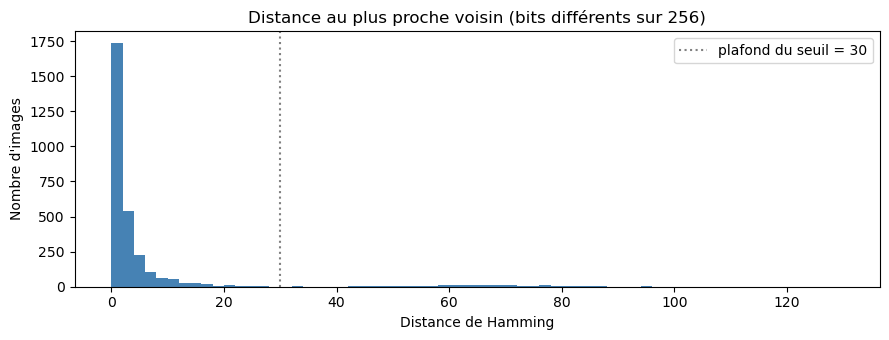

,groupes,plus_grand_groupe,images_dans_groupes_multiples
seuil,,,
6,1080,37,2550
10,805,42,2697
16,593,42,2786
20,551,42,2807
24,528,48,2821
30,514,48,2827
36,508,48,2829
40,503,48,2831
50,462,276,2848


Seuil choisi automatiquement : 30 bits (plus grand groupe autorisé : 89 images)


In [5]:
# Distance de chaque image à son plus proche voisin
nn = d.copy().astype(np.int32)
np.fill_diagonal(nn, 9999)
nearest = nn.min(axis=1)

plt.figure(figsize=(9, 3.5))
plt.hist(nearest, bins=range(0, 131, 2), color="steelblue")
plt.axvline(HAMMING_CAP, color="gray", linestyle=":", label=f"plafond du seuil = {HAMMING_CAP}")
plt.title("Distance au plus proche voisin (bits différents sur 256)")
plt.xlabel("Distance de Hamming"); plt.ylabel("Nombre d'images"); plt.legend()
plt.tight_layout(); plt.show()

# Balayage des seuils : on cherche le PLUS GRAND seuil qui franchit la queue de variantes
# sans fusionner des images différentes en grands groupes (regroupement en chaîne)
rows = []
for t in range(2, 51, 2):
    n_g, gid = connected_components(csr_matrix(d <= t), directed=False)
    sz = np.bincount(gid)
    rows.append({"seuil": t, "groupes": n_g, "plus_grand_groupe": int(sz.max()),
                 "images_dans_groupes_multiples": int(sz[sz > 1].sum())})
sweep = pd.DataFrame(rows).set_index("seuil")
display(sweep.loc[[t for t in (6, 10, 16, 20, 24, 30, 36, 40, 50) if t in sweep.index]])

if HAMMING_MAX is None:
    limit = max(3, int(MAX_GROUP_FRACTION * len(df)))
    ok = sweep[(sweep.index <= HAMMING_CAP) & (sweep["plus_grand_groupe"] <= limit)]
    HAMMING_MAX = int(ok.index.max()) if len(ok) else 2
    print(f"Seuil choisi automatiquement : {HAMMING_MAX} bits (plus grand groupe autorisé : {limit} images)")
else:
    print(f"Seuil imposé : {HAMMING_MAX} bits")

In [6]:
n_groups, group_id = connected_components(csr_matrix(d <= HAMMING_MAX), directed=False)
df["group"] = group_id
sizes = df["group"].value_counts()

print(f"Seuil utilisé : {HAMMING_MAX} bits")
print(f"Groupes : {n_groups} pour {len(df)} images  (≈ {n_groups} images réellement distinctes)")
print(f"Groupes de plusieurs images : {(sizes > 1).sum()} ({sizes[sizes > 1].sum()} images concernées)")
print(f"Taille du plus grand groupe : {sizes.max()}")
mixed = df.groupby("group")["label"].nunique()
print(f"Groupes aux étiquettes mélangées : {(mixed > 1).sum()}  (à examiner à la main si > 0)")

if sizes.max() > MAX_GROUP_FRACTION * len(df):
    print("ATTENTION : un groupe dépasse la taille autorisée (regroupement en chaîne). Impose un HAMMING_MAX plus bas.")
if n_groups < 30:
    raise ValueError(f"Seulement {n_groups} groupes : impossible de séparer proprement. Baisse HAMMING_MAX.")

Seuil utilisé : 30 bits
Groupes : 514 pour 2998 images  (≈ 514 images réellement distinctes)
Groupes de plusieurs images : 343 (2827 images concernées)
Taille du plus grand groupe : 48
Groupes aux étiquettes mélangées : 0  (à examiner à la main si > 0)


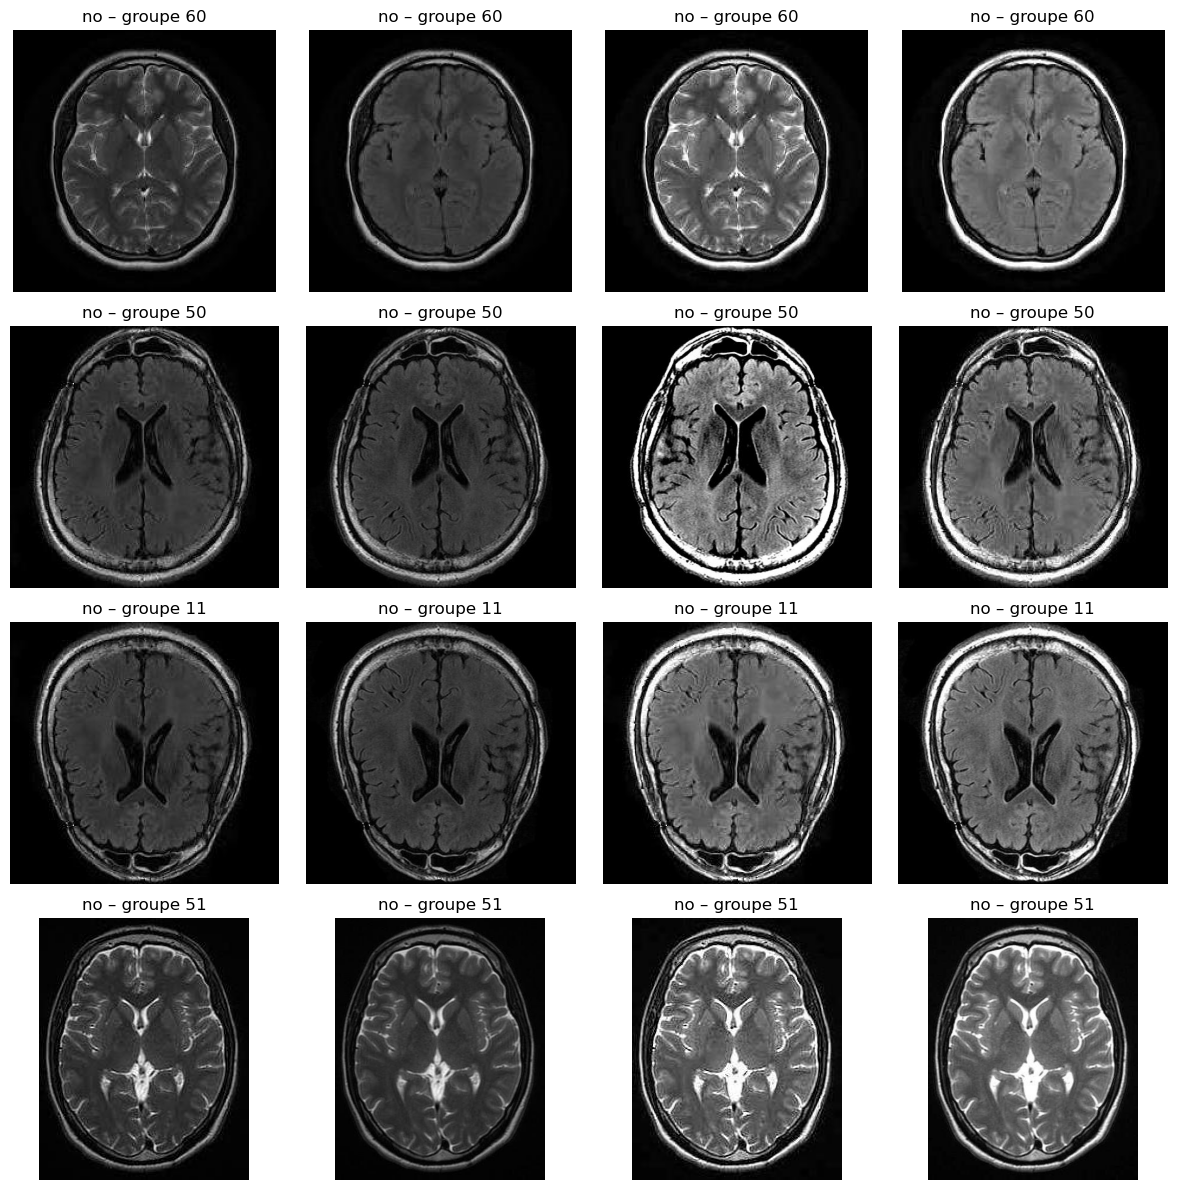

In [7]:
multi = sizes[sizes > 1].index[:4]
if len(multi) == 0:
    print("Aucun quasi-doublon détecté avec ce seuil.")
else:
    fig, axes = plt.subplots(len(multi), 4, figsize=(12, 3 * len(multi)), squeeze=False)
    for r, g in enumerate(multi):
        members = df[df["group"] == g].head(4)
        for c in range(4):
            ax = axes[r, c]; ax.axis("off")
            if c < len(members):
                row = members.iloc[c]
                with Image.open(row["path"]) as im:
                    ax.imshow(im.copy(), cmap="gray")
                ax.set_title(f"{row['label']} – groupe {g}")
    plt.tight_layout(); plt.show()

## 4. Les métadonnées permettent-elles de deviner la classe ? (version corrigée)

On entraîne une forêt aléatoire **sans regarder les pixels**, uniquement sur la taille, le format et le poids du fichier. **Correction par rapport à la v2** : la validation croisée est maintenant **groupée** (les copies d'une même image restent du même côté) et se fait après le regroupement.

- Score proche de **50 %** : aucun raccourci.
- Score nettement plus élevé (par exemple > 65 %) : le réseau pourrait « tricher » avec la taille ou la compression. Les étapes de prétraitement plus bas réduisent cet effet ; la sonde de la section 7 mesure ce qu'il en reste dans les pixels.

In [8]:
meta = df[["width", "height", "channels", "size_kb"]].copy()
meta["aspect_ratio"] = df["width"] / df["height"]
meta["not_jpeg"] = (df["format"] != "JPEG").astype(int)
y_meta = (df["label"] == "yes").astype(int)
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

def grouped_cv_accuracy(X):
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
    return cross_val_score(rf, X, y_meta, cv=cv, groups=df["group"], scoring="accuracy").mean()

all_score = grouped_cv_accuracy(meta.values)
print(f"Toutes les métadonnées ensemble (CV groupée) : {all_score:.1%}")
per_feature = {c: grouped_cv_accuracy(meta[[c]].values) for c in meta.columns}
display(pd.Series(per_feature, name="précision seule").sort_values(ascending=False).map("{:.1%}".format).to_frame())

if all_score > 0.65:
    print("ATTENTION : les métadonnées trahissent en partie la classe. Interprète les scores avec prudence.")
else:
    print("OK : pas de raccourci évident via les métadonnées.")

Toutes les métadonnées ensemble (CV groupée) : 88.1%


,précision seule
aspect_ratio,87.1%
height,85.2%
width,82.2%
size_kb,61.2%
channels,49.1%
not_jpeg,47.4%


ATTENTION : les métadonnées trahissent en partie la classe. Interprète les scores avec prudence.


## 5. Séparation train / validation / test (70 / 15 / 15, stratifiée, par groupes)

3 plis sur 20 pour le test, 3 pour la validation, 14 pour le train. Les deux cellules suivantes vérifient l'absence de fuite.

In [9]:
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, df["label"], df["group"])]

df["split"] = "train"
df.loc[np.concatenate(folds[:3]), "split"] = "test"
df.loc[np.concatenate(folds[3:6]), "split"] = "val"

summary = pd.crosstab(df["split"], df["label"], margins=True)
summary["% du total"] = (summary["All"] / len(df) * 100).round(1)
summary["groupes"] = [df.loc[df["split"] == s, "group"].nunique() if s != "All" else df["group"].nunique() for s in summary.index]
display(summary.loc[["train", "val", "test", "All"]])

label,no,yes,All,% du total,groupes
split,,,,,
train,1031,1044,2075,69.2,362
val,203,224,427,14.2,77
test,264,232,496,16.5,75
All,1498,1500,2998,100.0,514


In [14]:
idx = {s: np.where(df["split"].values == s)[0] for s in ("train", "val", "test")}

# 1) vérification stricte : aucune paire de la même famille ne traverse deux ensembles
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    m = int(d[np.ix_(idx[a], idx[b])].min())
    print(f"Distance minimale {a:5s} <-> {b:5s} : {m} bits (seuil de regroupement : {HAMMING_MAX})")
    assert m > HAMMING_MAX, "Fuite détectée entre deux ensembles"
print("OK : aucune paire d'images quasi identiques ne traverse deux ensembles.")

# 2) fuite résiduelle : images de val/test qui ressemblent encore un peu à une image du train
for name in ("val", "test"):
    nearest_train = d[np.ix_(idx[name], idx["train"])].min(axis=1)
    print(f"{name:5s} : {(nearest_train <= HAMMING_MAX + 5).sum():3d} / {len(nearest_train)} images ont un voisin du train à ≤ {HAMMING_MAX + 5} bits, "
          f"{(nearest_train <= HAMMING_MAX + 10).sum():3d} à ≤ {HAMMING_MAX + 10} bits")

Distance minimale train <-> val   : 31 bits (seuil de regroupement : 30)
Distance minimale train <-> test  : 39 bits (seuil de regroupement : 30)
Distance minimale val   <-> test  : 42 bits (seuil de regroupement : 30)
OK : aucune paire d'images quasi identiques ne traverse deux ensembles.
val   :  12 / 427 images ont un voisin du train à ≤ 35 bits,  28 à ≤ 40 bits
test  :   0 / 496 images ont un voisin du train à ≤ 35 bits,   9 à ≤ 40 bits


## 6. Prétraitement des images

Pour chaque image, dans cet ordre :

1. orientation EXIF corrigée et conversion en **RGB** ;
2. **recadrage** autour du cerveau (marge de 2 %, garde-fous si le fond est clair ou la zone minuscule) ;
3. **normalisation d'intensité** : le tissu est étalé entre le 1ᵉʳ et le 99,5ᵉ percentile, et le fond devient noir pur (certaines images ont un fond gris) ;
4. **égalisation de résolution** : le côté le plus long est ramené à `COMMON_RES` pixels, pour que toutes les images aient le même niveau de détail une fois agrandies ;
5. redimensionnement avec **conservation du rapport hauteur/largeur**, remplissage noir, jusqu'à 224 × 224 ;
6. enregistrement en **PNG sans perte**.

Chaque étape se désactive avec les paramètres de la première cellule, ce qui permet de comparer les résultats avec et sans.

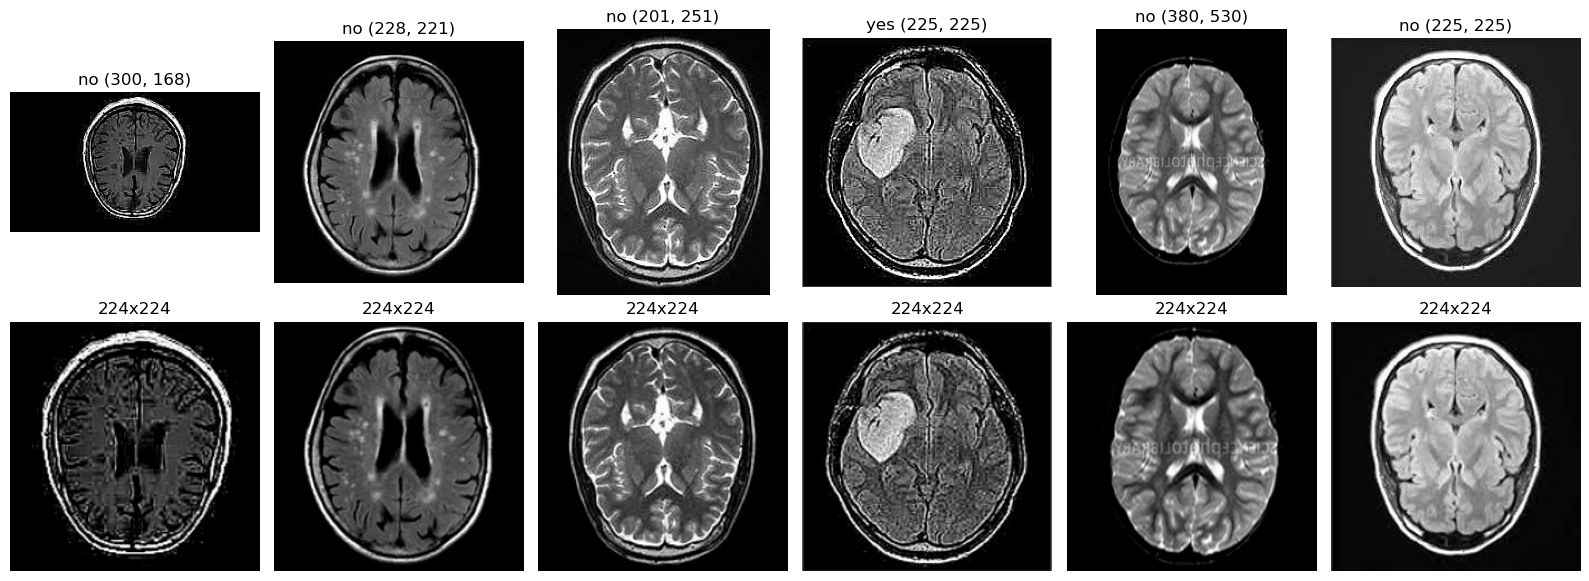

In [10]:
CROP_THRESHOLD = 20      # intensité (0-255) au-dessus de laquelle un pixel est du tissu

def crop_foreground(img, thresh=CROP_THRESHOLD, margin=0.02, min_count=3):
    g = np.asarray(img.convert("L"))
    h, w = g.shape
    border = np.concatenate([g[0], g[-1], g[:, 0], g[:, -1]])
    if np.median(border) > 60:                          # fond clair : on ne recadre pas
        return img
    mask = g > thresh
    rows = np.where(mask.sum(axis=1) >= min_count)[0]   # min_count ignore le bruit isolé
    cols = np.where(mask.sum(axis=0) >= min_count)[0]
    if len(rows) == 0 or len(cols) == 0:
        return img
    top, bottom, left, right = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
    if (bottom - top) * (right - left) < 0.2 * h * w:   # zone minuscule : on ne recadre pas
        return img
    mh, mw = int(margin * h), int(margin * w)
    return img.crop((max(0, left - mw), max(0, top - mh), min(w, right + mw), min(h, bottom + mh)))

def normalize_intensity(img, low=1.0, high=99.5):
    g = np.asarray(img.convert("L"), dtype=np.float32)
    tissue = g[g > CROP_THRESHOLD]
    if tissue.size < 100:
        return img
    lo, hi = np.percentile(tissue, [low, high])
    if hi - lo < 10:
        return img
    out = np.clip((g - lo) / (hi - lo), 0.0, 1.0) * 255.0     # le fond (<= lo) devient 0
    return Image.fromarray(out.astype(np.uint8)).convert("RGB")

def equalize_resolution(img, common=COMMON_RES):
    w, h = img.size
    longest = max(w, h)
    if longest <= common:
        return img
    scale = common / longest
    return img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.LANCZOS)

def prepare_image(path, size=IMG_SIZE):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
    if USE_CROP:
        im = crop_foreground(im)
    if NORMALIZE_INTENSITY:
        im = normalize_intensity(im)
    if EQUALIZE_RESOLUTION:
        im = equalize_resolution(im)
    return ImageOps.pad(im, (size, size), method=Image.BICUBIC, color=(0, 0, 0), centering=(0.5, 0.5))

# Contrôle visuel : originales (haut) / prétraitées (bas)
sample = df.sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 6, figsize=(16, 6))
for c, (_, row) in enumerate(sample.iterrows()):
    with Image.open(row["path"]) as im:
        axes[0, c].imshow(im.copy(), cmap="gray"); axes[0, c].set_title(f"{row['label']} {im.size}")
    axes[1, c].imshow(prepare_image(row["path"])); axes[1, c].set_title(f"{IMG_SIZE}x{IMG_SIZE}")
    axes[0, c].axis("off"); axes[1, c].axis("off")
plt.tight_layout(); plt.show()

In [11]:
# Écriture de toutes les images prétraitées. On ne supprime jamais un ancien dossier :
# s'il existe déjà, un nouveau dossier data_prepared_xxxx est créé (Windows peut refuser de supprimer des fichiers ouverts).
if PREP_DIR.exists():
    PREP_DIR = Path(tempfile.mkdtemp(prefix=f"{PREP_DIR.name}_", dir=PREP_DIR.parent))
    print(f"Ancien dossier conservé. Nouveaux résultats : {PREP_DIR}")
else:
    PREP_DIR.mkdir(parents=True, exist_ok=True)

prep_paths, failures = [], []
for i, row in df.iterrows():
    out = PREP_DIR / row["split"] / row["label"] / f"{i:05d}.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    try:
        prepare_image(row["path"]).save(out)
        prep_paths.append(str(out))
    except (UnidentifiedImageError, OSError, ValueError) as error:
        prep_paths.append(None); failures.append((row["path"], str(error)))

df["prep_path"] = prep_paths
if failures:
    print(f"{len(failures)} image(s) non prétraitée(s), retirées :", failures[:5])
    df = df[df["prep_path"].notna()].reset_index(drop=True)

df.to_csv("splits.csv", index=False)
print(f"{len(df)} images prétraitées dans {PREP_DIR}/ | séparation enregistrée dans splits.csv")
display(df.groupby(["split", "label"]).size().unstack())

Ancien dossier conservé. Nouveaux résultats : C:\Users\Mahamadou\Documents\DL\Tumeur\data_prepared_i7lv9930
2998 images prétraitées dans C:\Users\Mahamadou\Documents\DL\Tumeur\data_prepared_i7lv9930/ | séparation enregistrée dans splits.csv


label,no,yes
split,,
test,264,232
train,1031,1044
val,203,224


## 7. Sonde de raccourcis sur les pixels

On calcule sur les images **prétraitées** quelques indices qui ne décrivent pas l'anatomie : luminosité moyenne, contraste, netteté (variance du laplacien), proportion de pixels non noirs, luminosité des coins et rapport hauteur/largeur de la zone non noire. Une forêt aléatoire (validation croisée **groupée**) tente de deviner la classe avec ces seuls indices.

- ≈ 50-65 % : pas de raccourci évident.
- ≥ 75 % : le réseau peut s'appuyer sur la qualité d'image plutôt que sur la tumeur. Teste alors des paramètres plus agressifs (`COMMON_RES` plus bas) et reste prudent avec tes scores.

Remarque : la proportion de pixels non noirs et la luminosité du tissu peuvent aussi être légèrement liées à une vraie lésion ; cette sonde est un **indicateur**, pas une preuve.

In [13]:
def quality_features(path):
    with Image.open(path) as im:
        a = np.asarray(im.convert("L"), dtype=np.float32)
    lap = 4 * a - np.roll(a, 1, 0) - np.roll(a, -1, 0) - np.roll(a, 1, 1) - np.roll(a, -1, 1)
    fg = a > CROP_THRESHOLD
    if fg.any():
        ys, xs = np.where(fg)
        aspect = (xs.max() - xs.min() + 1) / (ys.max() - ys.min() + 1)
        tissue_median = float(np.median(a[fg]))
    else:
        aspect, tissue_median = 1.0, 0.0
    corners = [a[:16, :16].mean(), a[:16, -16:].mean(), a[-16:, :16].mean(), a[-16:, -16:].mean()]
    return {"mean": a.mean(), "std": a.std(), "tissue_median": tissue_median, "fg_fraction": fg.mean(),
            "sharpness": lap.var(), "corner_mean": float(np.mean(corners)), "bbox_aspect": aspect}

pix = pd.DataFrame([quality_features(p) for p in df["prep_path"]])
y_pix = (df["label"] == "yes").astype(int)

def grouped_cv_pixels(X):
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
    return cross_val_score(rf, X, y_pix, cv=cv, groups=df["group"], scoring="accuracy").mean()

pix_score = grouped_cv_pixels(pix.values)
print(f"Indices de qualité d'image seuls (CV groupée) : {pix_score:.1%}")
display(pd.Series({c: grouped_cv_pixels(pix[[c]].values) for c in pix.columns}, name="précision seule")
        .sort_values(ascending=False).map("{:.1%}".format).to_frame())
if pix_score >= 0.75:
    print("ATTENTION : les indices de qualité d'image prédisent fortement la classe.")
else:
    print("OK : les indices de qualité d'image seuls ne suffisent pas à deviner la classe.")

Indices de qualité d'image seuls (CV groupée) : 87.7%


,précision seule
bbox_aspect,68.7%
std,66.3%
mean,64.9%
fg_fraction,60.4%
sharpness,57.4%
tissue_median,57.3%
corner_mean,50.9%


ATTENTION : les indices de qualité d'image prédisent fortement la classe.


## 8. Statistiques et poids de classes (train uniquement)

In [14]:
train_paths = df.loc[df["split"] == "train", "prep_path"].tolist()
s = np.zeros(3); s2 = np.zeros(3); n = 0
for p in train_paths:
    with Image.open(p) as im:
        x = np.asarray(im, dtype=np.float64) / 255.0
    s += x.sum(axis=(0, 1)); s2 += (x ** 2).sum(axis=(0, 1)); n += x.shape[0] * x.shape[1]
train_mean = s / n
train_std = np.sqrt(s2 / n - train_mean ** 2)

train_counts = df.loc[df["split"] == "train", "label"].value_counts().reindex(["no", "yes"])
class_weights = (train_counts.sum() / (2 * train_counts)).round(3)

stats = {
    "prep_dir": str(PREP_DIR),
    "img_size": IMG_SIZE,
    "prep_settings": {"crop": USE_CROP, "normalize_intensity": NORMALIZE_INTENSITY,
                      "equalize_resolution": EQUALIZE_RESOLUTION, "common_res": COMMON_RES},
    "hamming_max": HAMMING_MAX,
    "train_mean": train_mean.round(4).tolist(),
    "train_std": train_std.round(4).tolist(),
    "class_to_idx": {"no": 0, "yes": 1},
    "class_weights": class_weights.to_dict(),
}
json.dump(stats, open("stats.json", "w"), indent=2)
print("moyenne (train) :", train_mean.round(3), "| écart-type (train) :", train_std.round(3))
print("poids de classes :", class_weights.to_dict(), "(≈ 1 : classes équilibrées)")

moyenne (train) : [0.234 0.234 0.234] | écart-type (train) : [0.275 0.275 0.275]
poids de classes : {'no': 1.006, 'yes': 0.994} (≈ 1 : classes équilibrées)


## 9. DataLoaders PyTorch avec data augmentation (train uniquement)

Ajout par rapport à la v2 : un **flou gaussien aléatoire** qui empêche le réseau de s'appuyer sur la netteté exacte des images. Sous Windows, garde `num_workers=0` dans un notebook.

In [15]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms as T

torch.manual_seed(SEED)
if USE_IMAGENET_STATS:
    MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
else:
    MEAN, STD = train_mean.tolist(), train_std.tolist()

train_tf = T.Compose([
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(10),
    T.RandomAffine(degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.RandomApply([T.GaussianBlur(kernel_size=5, sigma=(0.1, 1.5))], p=0.3),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

train_ds = datasets.ImageFolder(PREP_DIR / "train", transform=train_tf)
val_ds = datasets.ImageFolder(PREP_DIR / "val", transform=eval_tf)
test_ds = datasets.ImageFolder(PREP_DIR / "test", transform=eval_tf)

BATCH_SIZE = 32
g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print("classes :", train_ds.class_to_idx)
print(f"images : train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")
print("lot :", tuple(xb.shape), "| étiquettes :", yb[:8].tolist())

classes : {'no': 0, 'yes': 1}
images : train=2075, val=427, test=496
lot : (32, 3, 224, 224) | étiquettes : [0, 0, 1, 1, 1, 1, 1, 1]


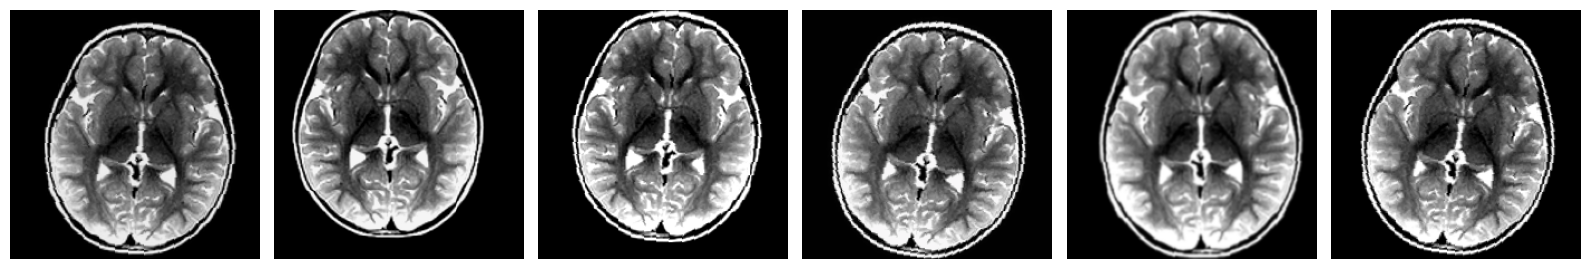

In [20]:
# Contrôle visuel de l'augmentation : 6 versions augmentées d'une même image du train
from torchvision.datasets.folder import default_loader
img0 = default_loader(train_ds.samples[0][0])
mean_t = torch.tensor(MEAN).view(3, 1, 1); std_t = torch.tensor(STD).view(3, 1, 1)

fig, axes = plt.subplots(1, 6, figsize=(16, 3))
for ax in axes:
    ax.imshow((train_tf(img0) * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy()); ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Entraînement en deux étapes (EfficientNet-B0 pré-entraîné)

1. **Étape 1 – tête seule** : le backbone est gelé, on entraîne la dernière couche (comme dans votre version).
2. **Étape 2 – fine-tuning** : on dégèle les derniers blocs du backbone (`features[6:]`) avec un taux d'apprentissage plus faible et une planification cosinus. Les couches de normalisation (BatchNorm) restent figées.

La sélection du meilleur modèle et l'arrêt anticipé se font sur la **perte de validation**. Le jeu de test n'est jamais utilisé avant la section 12.

Sur **CPU**, l'étape 2 est nettement plus lente : mets `RUN_FINE_TUNING = False` pour t'arrêter après l'étape 1.

In [16]:
import torch.nn.functional as F
from torchvision import models
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix, classification_report)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Appareil utilisé :", device)

STAGE1_EPOCHS = 15
RUN_FINE_TUNING = True
STAGE2_EPOCHS = 10
PATIENCE = 4
CHECKPOINT_PATH = Path("effnet_b0_best.pt")

if train_ds.class_to_idx != {"no": 0, "yes": 1}:
    raise ValueError(f"Ordre de classes inattendu : {train_ds.class_to_idx}")

model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
for parameter in model.features.parameters():
    parameter.requires_grad = False
model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, 1)
model = model.to(device)

positive_count = sum(train_ds.targets)
negative_count = len(train_ds.targets) - positive_count
pos_weight = torch.tensor([negative_count / positive_count], dtype=torch.float32, device=device)
criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)

def compute_metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred, zero_division=0),
        "recall": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0),
        "auc": roc_auc_score(y, p),
    }

def run_epoch(loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    if training:
        model.features.eval()          # BatchNorm du backbone figé
    total_loss, targets_all, probs_all = 0.0, [], []
    for images, targets in loader:
        images = images.to(device)
        targets_float = targets.to(device=device, dtype=torch.float32).unsqueeze(1)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets_float)
            if training:
                loss.backward()
                optimizer.step()
        total_loss += loss.item() * images.size(0)
        targets_all.extend(targets.tolist())
        probs_all.extend(torch.sigmoid(logits).detach().squeeze(1).cpu().tolist())
    return total_loss / len(loader.dataset), np.asarray(targets_all), np.asarray(probs_all)

history, best_val_loss, best_state = [], float("inf"), None

def fit(max_epochs, optimizer, scheduler=None, patience=PATIENCE, stage=""):
    global best_val_loss, best_state
    wait = 0
    for epoch in range(1, max_epochs + 1):
        train_loss, _, _ = run_epoch(train_loader, optimizer)
        val_loss, val_y, val_p = run_epoch(val_loader)
        m = compute_metrics(val_y, val_p)
        history.append({"stage": stage, "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, **m})
        print(f"[{stage}] époque {epoch:02d}/{max_epochs} | train_loss={train_loss:.4f} val_loss={val_loss:.4f} "
              f"| rappel={m['recall']:.3f} F1={m['f1']:.3f} AUC={m['auc']:.3f}")
        if scheduler is not None:
            scheduler.step()
        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"[{stage}] arrêt anticipé : la perte de validation ne s'améliore plus.")
                break

Appareil utilisé : cpu


In [17]:
# Étape 1 : tête seule
optimizer1 = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
fit(STAGE1_EPOCHS, optimizer1, stage="1-tête")

[1-tête] époque 01/15 | train_loss=0.4547 val_loss=0.3353 | rappel=0.964 F1=0.902 AUC=0.968
[1-tête] époque 02/15 | train_loss=0.2946 val_loss=0.2655 | rappel=0.969 F1=0.927 AUC=0.976
[1-tête] époque 03/15 | train_loss=0.2500 val_loss=0.2304 | rappel=0.964 F1=0.952 AUC=0.978
[1-tête] époque 04/15 | train_loss=0.2170 val_loss=0.2215 | rappel=0.982 F1=0.942 AUC=0.979
[1-tête] époque 05/15 | train_loss=0.1955 val_loss=0.2057 | rappel=0.987 F1=0.955 AUC=0.981
[1-tête] époque 06/15 | train_loss=0.1804 val_loss=0.1983 | rappel=0.987 F1=0.951 AUC=0.982
[1-tête] époque 07/15 | train_loss=0.1781 val_loss=0.1846 | rappel=0.982 F1=0.963 AUC=0.983
[1-tête] époque 08/15 | train_loss=0.1695 val_loss=0.1798 | rappel=0.987 F1=0.963 AUC=0.984
[1-tête] époque 09/15 | train_loss=0.1622 val_loss=0.1699 | rappel=0.987 F1=0.967 AUC=0.984
[1-tête] époque 10/15 | train_loss=0.1468 val_loss=0.1614 | rappel=0.982 F1=0.965 AUC=0.984
[1-tête] époque 12/15 | train_loss=0.1316 val_loss=0.1640 | rappel=0.987 F1=0.96

[2-fine-tuning] époque 01/10 | train_loss=0.1055 val_loss=0.0967 | rappel=0.991 F1=0.969 AUC=0.995
[2-fine-tuning] époque 02/10 | train_loss=0.0487 val_loss=0.0754 | rappel=0.991 F1=0.987 AUC=0.996
[2-fine-tuning] époque 03/10 | train_loss=0.0297 val_loss=0.0785 | rappel=0.982 F1=0.982 AUC=0.997
[2-fine-tuning] époque 04/10 | train_loss=0.0165 val_loss=0.0994 | rappel=0.991 F1=0.984 AUC=0.997
[2-fine-tuning] époque 05/10 | train_loss=0.0127 val_loss=0.0773 | rappel=0.987 F1=0.984 AUC=0.998
[2-fine-tuning] époque 06/10 | train_loss=0.0027 val_loss=0.0739 | rappel=0.987 F1=0.984 AUC=0.999
[2-fine-tuning] époque 07/10 | train_loss=0.0064 val_loss=0.0838 | rappel=0.991 F1=0.987 AUC=0.998
[2-fine-tuning] époque 08/10 | train_loss=0.0045 val_loss=0.0809 | rappel=0.987 F1=0.984 AUC=0.998
[2-fine-tuning] époque 09/10 | train_loss=0.0048 val_loss=0.1013 | rappel=0.991 F1=0.984 AUC=0.998
[2-fine-tuning] époque 10/10 | train_loss=0.0019 val_loss=0.0931 | rappel=0.991 F1=0.987 AUC=0.998
[2-fine-tu

,stage,epoch,train_loss,val_loss,accuracy,precision,recall,f1,auc
12,1-tête,13,0.1311,0.1601,0.9602,0.9404,0.9866,0.9630,0.9853
13,1-tête,14,0.1245,0.1671,0.9532,0.9286,0.9866,0.9567,0.9846
14,1-tête,15,0.1196,0.1577,0.9555,0.9325,0.9866,0.9588,0.9850
22,2-fine-tuning,8,0.0045,0.0809,0.9836,0.9822,0.9866,0.9844,0.9980
23,2-fine-tuning,9,0.0048,0.1013,0.9836,0.9780,0.9911,0.9845,0.9980
24,2-fine-tuning,10,0.0019,0.0931,0.9859,0.9823,0.9911,0.9867,0.9982


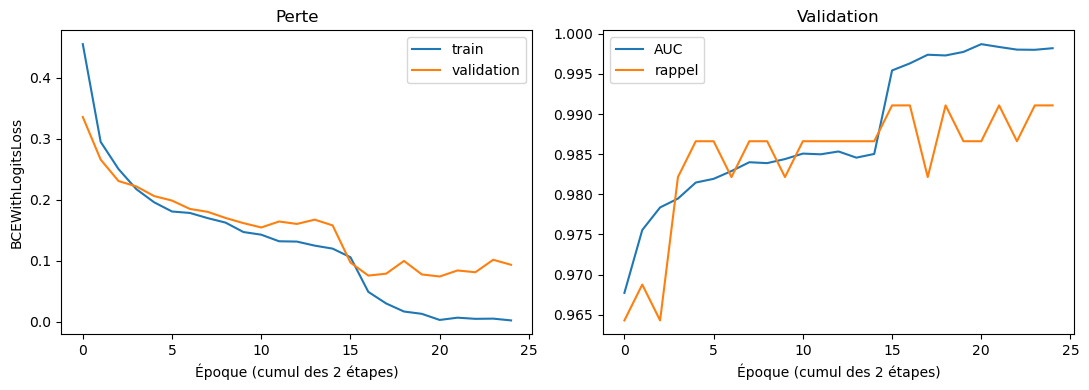

In [18]:
# Étape 2 : fine-tuning des derniers blocs (on repart du meilleur modèle de l'étape 1)
if RUN_FINE_TUNING:
    model.load_state_dict(best_state)
    for parameter in model.features[6:].parameters():
        parameter.requires_grad = True
    optimizer2 = torch.optim.AdamW([
        {"params": model.features[6:].parameters(), "lr": 1e-4},
        {"params": model.classifier.parameters(), "lr": 3e-4},
    ], weight_decay=1e-4)
    scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=STAGE2_EPOCHS)
    fit(STAGE2_EPOCHS, optimizer2, scheduler=scheduler2, stage="2-fine-tuning")

model.load_state_dict(best_state)          # on garde le meilleur modèle selon la perte de validation
history_df = pd.DataFrame(history)
display(history_df.groupby("stage").tail(3).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_df["train_loss"].values, label="train"); axes[0].plot(history_df["val_loss"].values, label="validation")
axes[0].set(xlabel="Époque (cumul des 2 étapes)", ylabel="BCEWithLogitsLoss", title="Perte"); axes[0].legend()
axes[1].plot(history_df["auc"].values, label="AUC"); axes[1].plot(history_df["recall"].values, label="rappel")
axes[1].set(xlabel="Époque (cumul des 2 étapes)", title="Validation"); axes[1].legend()
plt.tight_layout(); plt.show()

## 11. Choix du seuil de décision (sur la validation)

En imagerie médicale, manquer une tumeur (faux négatif) est plus grave qu'une fausse alerte. On choisit donc, **sur la validation uniquement**, le seuil qui donne la meilleure précision parmi ceux qui atteignent un **rappel d'au moins 95 %**.

In [19]:
MIN_RECALL = 0.95
_, val_y, val_p = run_epoch(val_loader)

def choose_threshold(y, p, min_recall=MIN_RECALL):
    best = None
    for thr in np.arange(0.05, 0.96, 0.01):
        m = compute_metrics(y, p, thr)
        if m["recall"] >= min_recall and (best is None or m["precision"] > best[1]["precision"]):
            best = (float(thr), m)
    if best is None:                                  # rappel cible inatteignable : on maximise le F1
        scored = [(float(t), compute_metrics(y, p, t)) for t in np.arange(0.05, 0.96, 0.01)]
        best = max(scored, key=lambda item: item[1]["f1"])
        print(f"Rappel ≥ {min_recall:.0%} inatteignable sur la validation : seuil choisi par F1.")
    return best

threshold, val_m = choose_threshold(val_y, val_p)
print(f"Seuil choisi : {threshold:.2f}")
print({k: round(v, 3) for k, v in val_m.items()})

torch.save({
    "state_dict": best_state,
    "class_to_idx": train_ds.class_to_idx,
    "img_size": IMG_SIZE, "mean": MEAN, "std": STD,
    "threshold": threshold,
    "prep_settings": stats["prep_settings"],
}, CHECKPOINT_PATH)
print(f"Modèle sauvegardé : {CHECKPOINT_PATH.resolve()}")

Seuil choisi : 0.07
{'accuracy': 0.988, 'precision': 0.982, 'recall': 0.996, 'f1': 0.989, 'auc': 0.999}
Modèle sauvegardé : C:\Users\Mahamadou\Documents\DL\Tumeur\effnet_b0_best.pt


## 12. Évaluation finale sur le test (à lancer une seule fois)

Les intervalles de confiance à 95 % sont calculés par **bootstrap sur les groupes** (on rééchantillonne des familles d'images, pas des images isolées). Comme le jeu contient beaucoup de quasi-doublons, le nombre d'images réellement distinctes dans le test est faible : les intervalles seront larges, et c'est normal.

Seuil utilisé : 0.07 | perte test : 0.0600 | groupes distincts dans le test : 75
accuracy  : 0.948   IC 95 % [0.902 ; 0.986]
precision : 0.902   IC 95 % [0.799 ; 0.978]
recall    : 0.996   IC 95 % [0.985 ; 1.000]
f1        : 0.947   IC 95 % [0.887 ; 0.987]
auc       : 0.998   IC 95 % [0.994 ; 1.000]

              precision    recall  f1-score   support

          no       1.00      0.91      0.95       264
         yes       0.90      1.00      0.95       232

    accuracy                           0.95       496
   macro avg       0.95      0.95      0.95       496
weighted avg       0.95      0.95      0.95       496



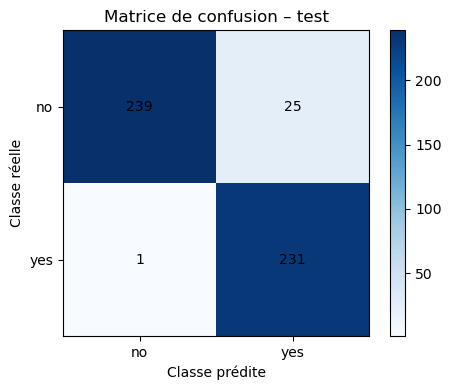

In [20]:
test_loss, test_y, test_p = run_epoch(test_loader)
test_pred = (test_p >= threshold).astype(int)
test_m = compute_metrics(test_y, test_p, threshold)

# groupes des images du test, dans l'ordre exact du DataLoader
path_to_group = {str(Path(p).resolve()): g for p, g in zip(df["prep_path"], df["group"])}
test_groups = np.array([path_to_group[str(Path(p).resolve())] for p, _ in test_ds.samples])

def group_bootstrap(y, p, groups, thr, n_boot=1000, seed=SEED):
    rng = np.random.default_rng(seed)
    uniq = np.unique(groups)
    members = {g: np.where(groups == g)[0] for g in uniq}
    out = {k: [] for k in ("accuracy", "precision", "recall", "f1", "auc")}
    for _ in range(n_boot):
        chosen = rng.choice(uniq, size=len(uniq), replace=True)
        sel = np.concatenate([members[g] for g in chosen])
        if len(np.unique(y[sel])) < 2:
            continue
        m = compute_metrics(y[sel], p[sel], thr)
        for k in out:
            out[k].append(m[k])
    return {k: (np.percentile(v, 2.5), np.percentile(v, 97.5)) for k, v in out.items()}

ci = group_bootstrap(test_y, test_p, test_groups, threshold)
print(f"Seuil utilisé : {threshold:.2f} | perte test : {test_loss:.4f} | groupes distincts dans le test : {len(np.unique(test_groups))}")
for k, v in test_m.items():
    print(f"{k:10s}: {v:.3f}   IC 95 % [{ci[k][0]:.3f} ; {ci[k][1]:.3f}]")

print()
print(classification_report(test_y, test_pred, target_names=["no", "yes"], zero_division=0))

matrix = confusion_matrix(test_y, test_pred, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
im_ = ax.imshow(matrix, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["no", "yes"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["no", "yes"])
for r in range(2):
    for c in range(2):
        ax.text(c, r, matrix[r, c], ha="center", va="center")
ax.set_xlabel("Classe prédite"); ax.set_ylabel("Classe réelle"); ax.set_title("Matrice de confusion – test")
fig.colorbar(im_, ax=ax); plt.tight_layout(); plt.show()

## 13. Analyse des erreurs et Grad-CAM

Le **Grad-CAM** montre les zones de l'image qui ont le plus poussé le modèle vers `yes`. Vérifie visuellement que la chaleur est sur le **tissu cérébral / la lésion** et non sur les bords, le texte ou le fond : c'est le meilleur test pour détecter un modèle qui triche.

Haut : faux négatifs (tumeur manquée). Bas : faux positifs.

Faux négatifs : 1 | faux positifs : 25


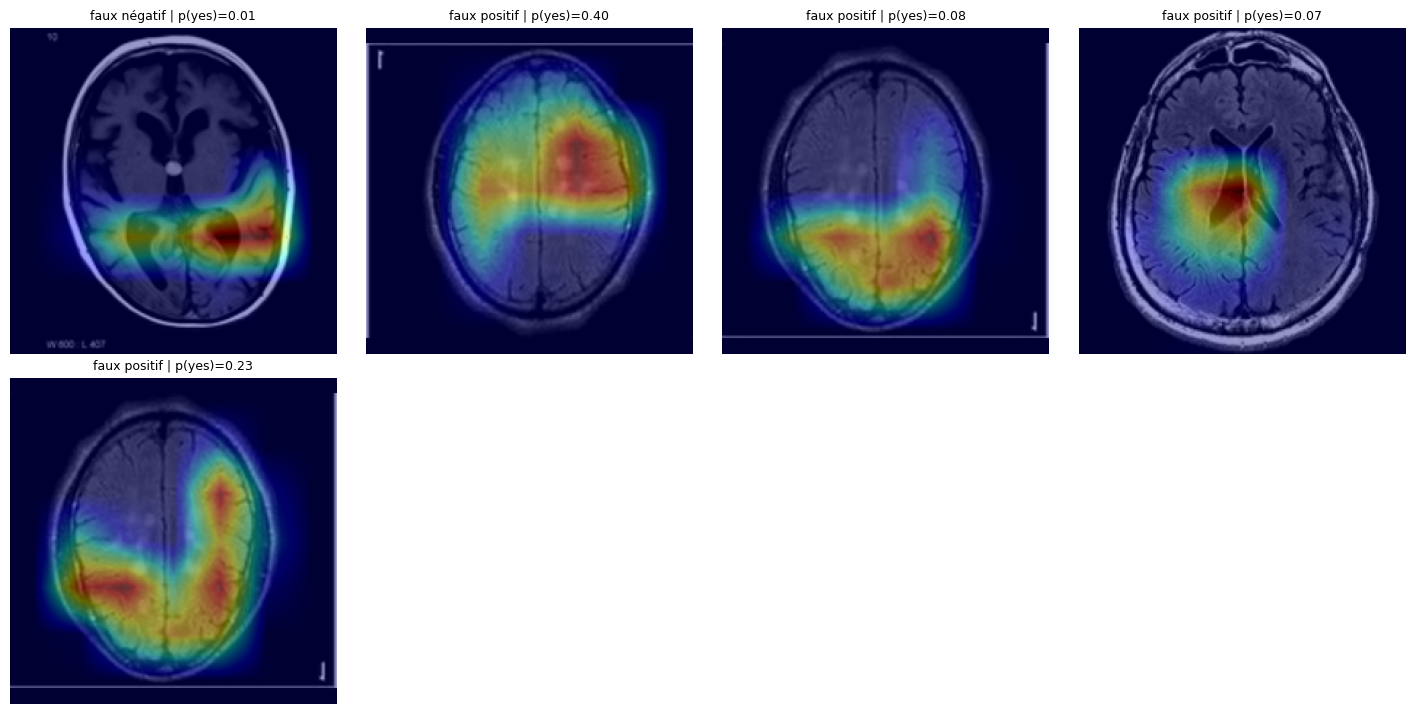

In [21]:
def grad_cam(path):
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device).clone().detach().requires_grad_(True)
    model.eval()
    feats = model.features(x)                                  # (1, 1280, 7, 7)
    logit = model.classifier(torch.flatten(model.avgpool(feats), 1))
    grads = torch.autograd.grad(logit.sum(), feats)[0]
    weights_ = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights_ * feats).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return np.asarray(img), cam.detach().cpu().numpy(), torch.sigmoid(logit).item()

test_paths = [p for p, _ in test_ds.samples]
false_neg = np.where((test_y == 1) & (test_pred == 0))[0]
false_pos = np.where((test_y == 0) & (test_pred == 1))[0]
print(f"Faux négatifs : {len(false_neg)} | faux positifs : {len(false_pos)}")

shown = [("faux négatif", i) for i in false_neg[:4]] + [("faux positif", i) for i in false_pos[:4]]
if not shown:
    print("Aucune erreur à afficher.")
else:
    cols = 4
    rows_ = int(np.ceil(len(shown) / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(3.6 * cols, 3.6 * rows_), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, (kind, i) in zip(axes.ravel(), shown):
        image_arr, cam, prob = grad_cam(test_paths[i])
        ax.imshow(image_arr); ax.imshow(cam, cmap="jet", alpha=0.4)
        ax.set_title(f"{kind} | p(yes)={prob:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

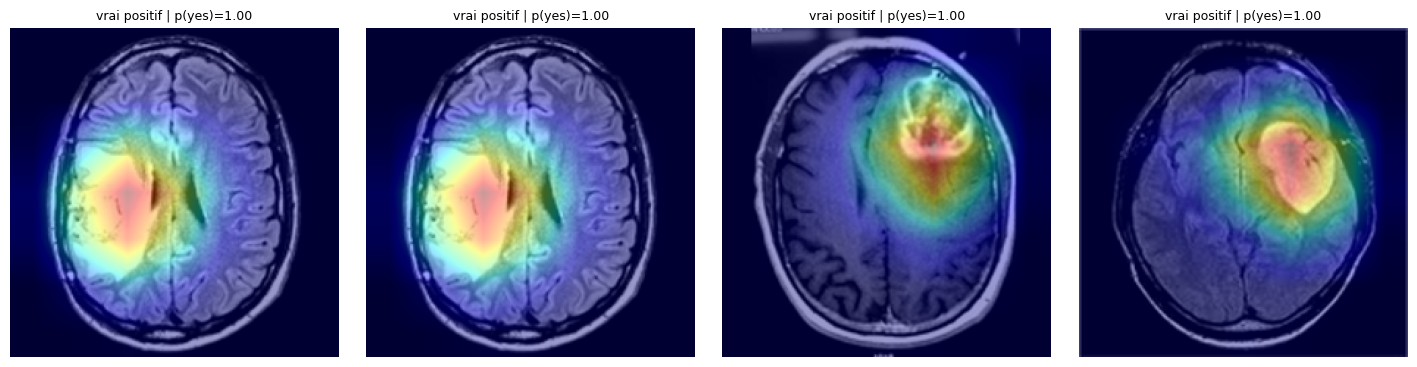

In [22]:
# Grad-CAM sur des prédictions correctes et confiantes (tumeurs détectées) : où regarde le modèle ?
true_pos = np.where((test_y == 1) & (test_pred == 1))[0]
best = true_pos[np.argsort(-test_p[true_pos])][:4] if len(true_pos) else []
if len(best):
    fig, axes = plt.subplots(1, len(best), figsize=(3.6 * len(best), 3.6), squeeze=False)
    for ax, i in zip(axes[0], best):
        image_arr, cam, prob = grad_cam(test_paths[i])
        ax.imshow(image_arr); ax.imshow(cam, cmap="jet", alpha=0.4); ax.axis("off")
        ax.set_title(f"vrai positif | p(yes)={prob:.2f}", fontsize=9)
    plt.tight_layout(); plt.show()

## 14. Sauvegarde et prédiction sur une nouvelle image

`predict_image()` applique **exactement le même prétraitement** que pendant l'entraînement. Utilise-la telle quelle dans une application Streamlit.

> Ce modèle est un **prototype de recherche** entraîné sur un jeu public contenant beaucoup de quasi-doublons. Il ne doit pas être utilisé pour un diagnostic.

In [23]:
def predict_image(path, thr=None):
    thr = threshold if thr is None else thr
    x = eval_tf(prepare_image(path)).unsqueeze(0).to(device)
    model.eval()
    with torch.no_grad():
        prob = torch.sigmoid(model(x)).item()
    return {"probabilite_tumeur": round(prob, 4), "prediction": "yes" if prob >= thr else "no", "seuil": round(thr, 2)}

model_card = {
    "modele": "EfficientNet-B0 (ImageNet) + tête binaire",
    "seuil": threshold,
    "validation": {k: round(v, 4) for k, v in val_m.items()},
    "test": {k: {"valeur": round(test_m[k], 4), "ic95": [round(ci[k][0], 4), round(ci[k][1], 4)]} for k in test_m},
    "images_distinctes_approx": int(df["group"].nunique()),
    "pretraitement": stats["prep_settings"],
    "avertissement": "Prototype de recherche, pas un dispositif médical.",
}
json.dump(model_card, open("model_card.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

example = df.loc[df["split"] == "test", "path"].iloc[0]
print("Exemple :", example, "->", predict_image(example))

Exemple : no\no1002.jpg -> {'probabilite_tumeur': 0.0013, 'prediction': 'no', 'seuil': 0.07}


## 15. Diagnostic du seuil : pourquoi le rappel du test est plus bas que celui de la validation

Dans l'exécution ci-dessus, l'**AUC du test est très élevée**, mais le **rappel au seuil choisi (0,67) est plus bas** que sur la validation. Les Grad-CAM des faux négatifs montrent d'ailleurs des **lésions bien visibles** avec une probabilité `p(yes)` entre 0,26 et 0,61 : le modèle voit la lésion, mais le seuil est trop strict. Le seuil a été choisi sur une validation de seulement quelques dizaines de familles d'images, donc il est instable.

Le tableau montre l'effet du seuil sur la validation **et** sur le test. **Ne choisis pas un nouveau seuil d'après le test** : il a déjà été regardé. Une règle fixée d'avance (rappel ≥ 98 % sur la validation) est donnée à titre indicatif.

,rappel (val),précision (val),rappel (test),précision (test),faux négatifs (test),faux positifs (test)
seuil,,,,,,
0.07,0.996,0.982,0.996,0.902,1,25
0.30,0.987,0.982,0.987,0.958,3,10
0.40,0.987,0.982,0.983,0.970,4,7
0.50,0.987,0.982,0.983,0.974,4,6
0.60,0.987,0.982,0.983,0.983,4,4
0.70,0.987,0.982,0.978,0.983,5,4
0.80,0.987,0.982,0.974,0.991,6,2


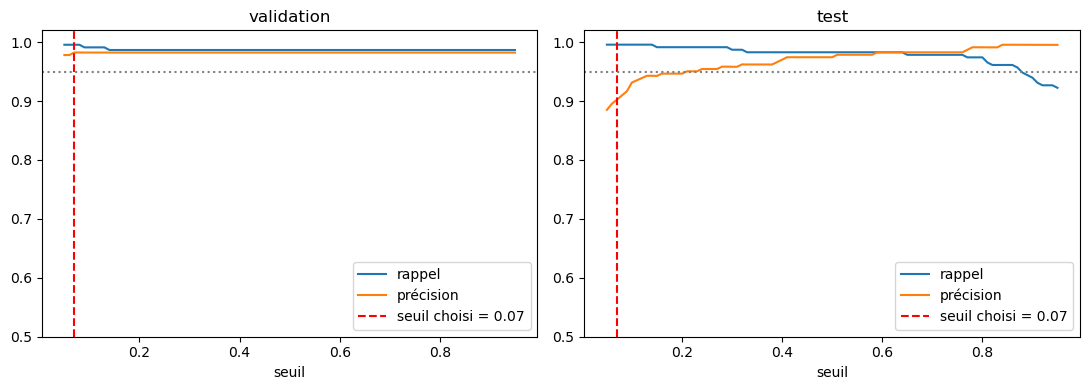

Règle plus prudente (rappel >= 98 % sur la VALIDATION) : seuil = 0.07
  validation : rappel = 0.996 | précision = 0.982
  test (à titre indicatif uniquement) : rappel = 0.996 | précision = 0.902
Le test ayant déjà été consulté, ce seuil n'est pas 'validé' : pour l'estimer proprement, utilise des prédictions
hors-pli (validation croisée par groupes) ou un jeu d'images d'une autre source.


In [24]:
grid = sorted(set([0.30, 0.40, 0.50, 0.60, 0.70, 0.80, round(float(threshold), 2)]))
rows = []
for thr in grid:
    mv = compute_metrics(val_y, val_p, thr)
    mt = compute_metrics(test_y, test_p, thr)
    rows.append({
        "seuil": thr,
        "rappel (val)": mv["recall"], "précision (val)": mv["precision"],
        "rappel (test)": mt["recall"], "précision (test)": mt["precision"],
        "faux négatifs (test)": int(((test_y == 1) & (test_p < thr)).sum()),
        "faux positifs (test)": int(((test_y == 0) & (test_p >= thr)).sum()),
    })
display(pd.DataFrame(rows).set_index("seuil").round(3))

ts = np.arange(0.05, 0.96, 0.01)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, y, p) in zip(axes, [("validation", val_y, val_p), ("test", test_y, test_p)]):
    ax.plot(ts, [recall_score(y, (p >= t).astype(int), zero_division=0) for t in ts], label="rappel")
    ax.plot(ts, [precision_score(y, (p >= t).astype(int), zero_division=0) for t in ts], label="précision")
    ax.axvline(threshold, color="red", linestyle="--", label=f"seuil choisi = {threshold:.2f}")
    ax.axhline(0.95, color="gray", linestyle=":")
    ax.set(title=name, xlabel="seuil", ylim=(0.5, 1.02)); ax.legend()
plt.tight_layout(); plt.show()

thr_safe, m_safe = choose_threshold(val_y, val_p, min_recall=0.98)
m_safe_test = compute_metrics(test_y, test_p, thr_safe)
print(f"Règle plus prudente (rappel >= 98 % sur la VALIDATION) : seuil = {thr_safe:.2f}")
print(f"  validation : rappel = {m_safe['recall']:.3f} | précision = {m_safe['precision']:.3f}")
print(f"  test (à titre indicatif uniquement) : rappel = {m_safe_test['recall']:.3f} | précision = {m_safe_test['precision']:.3f}")
print("Le test ayant déjà été consulté, ce seuil n'est pas 'validé' : pour l'estimer proprement, utilise des prédictions")
print("hors-pli (validation croisée par groupes) ou un jeu d'images d'une autre source.")

## 16. Contrôle anti-raccourci : performances par tranche de rapport hauteur/largeur

La section 4 a montré que le **rapport hauteur/largeur du fichier d'origine** à lui seul permet de deviner la classe dans environ 87 % des cas (validation croisée par groupes) : les deux classes viennent probablement de sources différentes. Un réseau pourrait en profiter sans regarder la tumeur.

Test simple : on découpe le **test** en tranches de rapport h/l (puis de hauteur et de poids de fichier) et on mesure l'AUC **à l'intérieur de chaque tranche**. Dans une même tranche, les métadonnées aident peu à séparer les classes : si l'AUC reste élevée partout, le réseau s'appuie sur autre chose que ce raccourci. On compare aussi avec une forêt aléatoire qui n'utilise **que les métadonnées**.

Lecture : AUC de chaque tranche ≥ 0,95 → bon signe. Chute dans certaines tranches → raccourci probable. Les tranches avec moins de 5 images d'une classe ne sont pas notées.

In [25]:
from sklearn.metrics import roc_auc_score

path_to_row = {str(Path(p).resolve()): i for i, p in enumerate(df["prep_path"])}
test_rows = np.array([path_to_row[str(Path(p).resolve())] for p, _ in test_ds.samples])
tm = df.iloc[test_rows].reset_index(drop=True).copy()
assert (tm["label"].map({"no": 0, "yes": 1}).values == test_y).all(), "Désalignement entre test_ds et df"
tm["y"], tm["p"], tm["pred"] = test_y, test_p, (test_p >= threshold).astype(int)
tm["aspect_ratio"] = tm["width"] / tm["height"]
df_aspect = df["width"] / df["height"]

def strata_report(feature, q=5):
    ref = df_aspect if feature == "aspect_ratio" else df[feature]
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    bins = pd.cut(tm[feature], edges)
    rows = []
    for b in bins.cat.categories:
        g = tm[bins == b]
        n_no, n_yes = int((g["y"] == 0).sum()), int((g["y"] == 1).sum())
        rows.append({
            "tranche": str(b), "n_no": n_no, "n_yes": n_yes,
            "AUC": roc_auc_score(g["y"], g["p"]) if min(n_no, n_yes) >= 5 else np.nan,
            "rappel": ((g["pred"] == 1) & (g["y"] == 1)).sum() / n_yes if n_yes else np.nan,
            "spécificité": ((g["pred"] == 0) & (g["y"] == 0)).sum() / n_no if n_no else np.nan,
        })
    return pd.DataFrame(rows).set_index("tranche")

def weighted_auc(rep):
    ok = rep.dropna(subset=["AUC"])
    w = np.minimum(ok["n_no"], ok["n_yes"])
    return float((ok["AUC"] * w).sum() / w.sum()) if len(ok) and w.sum() > 0 else float("nan")

reports = {}
for feature in ("aspect_ratio", "height", "size_kb"):
    reports[feature] = strata_report(feature)
    print(f"\n=== Test par tranches de {feature} ===")
    display(reports[feature].round(3))
    print(f"AUC pondérée par tranche : {weighted_auc(reports[feature]):.3f}")

# Plafond atteignable avec les seules métadonnées (forêt aléatoire entraînée sur le train, évaluée sur le test)
def meta_frame(frame):
    out = frame[["width", "height", "channels", "size_kb"]].copy()
    out["aspect_ratio"] = frame["width"] / frame["height"]
    out["not_jpeg"] = (frame["format"] != "JPEG").astype(int)
    return out

tr = df[df["split"] == "train"]
rf_meta = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)
rf_meta.fit(meta_frame(tr), (tr["label"] == "yes").astype(int))
meta_auc = roc_auc_score(test_y, rf_meta.predict_proba(meta_frame(tm))[:, 1])
cnn_auc = roc_auc_score(test_y, test_p)
print(f"\nAUC sur le test : réseau = {cnn_auc:.3f} | métadonnées seules = {meta_auc:.3f}")

worst = reports["aspect_ratio"]["AUC"].min()
if np.isnan(worst):
    print("Pas assez d'images par tranche pour conclure.")
elif worst >= 0.95:
    print(f"OK : l'AUC reste >= 0,95 dans chaque tranche de rapport h/l (minimum {worst:.3f}).")
else:
    print(f"ATTENTION : l'AUC tombe à {worst:.3f} dans au moins une tranche de rapport h/l : raccourci possible.")

# On ajoute ces contrôles à la fiche du modèle
model_card["controles"] = {
    "metadonnees_seules_cv_groupee": round(float(all_score), 3),
    "indices_pixels_seuls_cv_groupee": round(float(pix_score), 3),
    "auc_test_metadonnees_seules": round(float(meta_auc), 3),
    "auc_test_reseau": round(float(cnn_auc), 3),
    "auc_ponderee_par_tranche_rapport_hl": round(weighted_auc(reports["aspect_ratio"]), 3),
}
try:
    with open("model_card.json", "w", encoding="utf-8") as f:
        json.dump(model_card, f, ensure_ascii=False, indent=2)
except OSError as error:
    print("model_card.json n'a pas pu être écrit (fichier ouvert ailleurs ?) :", error)


=== Test par tranches de aspect_ratio ===


,n_no,n_yes,AUC,rappel,spécificité
tranche,,,,,
"(-inf, 0.804]",49,63,1.000,1.00,0.980
"(0.804, 0.86]",2,49,NaN,1.00,0.500
"(0.86, 0.953]",62,50,0.999,0.98,0.984
"(0.953, 1.0]",59,61,0.999,1.00,0.983
"(1.0, inf]",92,9,1.000,1.00,0.772


AUC pondérée par tranche : 1.000

=== Test par tranches de height ===


,n_no,n_yes,AUC,rappel,spécificité
tranche,,,,,
"(-inf, 225.0]",90,25,1.000,1.000,0.844
"(225.0, 255.0]",74,9,0.998,1.000,0.959
"(255.0, 340.0]",19,80,1.000,1.000,0.947
"(340.0, 442.0]",44,56,1.000,1.000,0.864
"(442.0, inf]",37,62,0.998,0.984,0.973


AUC pondérée par tranche : 0.999

=== Test par tranches de size_kb ===


,n_no,n_yes,AUC,rappel,spécificité
tranche,,,,,
"(-inf, 9.015]",87,16,1.000,1.000,0.862
"(9.015, 12.577]",69,31,0.998,1.000,0.971
"(12.577, 18.502]",29,51,0.993,1.000,0.862
"(18.502, 28.407]",34,60,1.000,1.000,1.000
"(28.407, inf]",45,74,0.995,0.986,0.844


AUC pondérée par tranche : 0.997

AUC sur le test : réseau = 0.998 | métadonnées seules = 0.927
OK : l'AUC reste >= 0,95 dans chaque tranche de rapport h/l (minimum 0.999).


## 17. Ablation : comparer les réglages de prétraitement

Les paramètres `NORMALIZE_INTENSITY` et `EQUALIZE_RESOLUTION` (première cellule) **neutralisent** respectivement la luminosité du fond et la netteté. La configuration de référence est **les deux à `True`**. On relance le pipeline avec ces réglages à `False` et on compare :

- score **plus élevé** quand on désactive une neutralisation → le réseau profite de cet indice (raccourci possible) ;
- score **identique** → le réseau n'en dépend pas.

Deux façons de produire les autres configurations :

1. **Dans le notebook** : change les paramètres de la première cellule, *Restart & Run All*, puis lance la cellule « Archivage ».
2. **Automatiquement** : le script `run_ablation.py` (fourni avec ce notebook) relance tout le pipeline depuis un terminal, par exemple
   `python run_ablation.py --normalize 0 --equalize 1`, et archive lui-même les résultats. Lance les 3 autres configurations l'une après l'autre : (0,1), (1,0), (0,0).

Chaque exécution refait le prétraitement et l'entraînement : prévois du temps sur CPU.

In [26]:
import shutil

# Archivage des résultats de l'exécution courante (le nom dépend des paramètres actifs en haut du notebook)
tag = f"norm_{NORMALIZE_INTENSITY}_eqres_{EQUALIZE_RESOLUTION}"
nom_archive = f"results_{tag}.json"
shutil.copy("model_card.json", nom_archive)
if CHECKPOINT_PATH.exists():
    shutil.copy(CHECKPOINT_PATH, f"effnet_b0_{tag}.pt")
print(f"Résultats archivés dans : {nom_archive}")

Résultats archivés dans : results_norm_True_eqres_True.json


,normalisation,égalisation,seuil (val),AUC test,IC95 AUC,rappel test,précision test,F1 test,AUC métadonnées seules
0,True,True,0.07,0.9979,[0.994 ; 1.000],0.9957,0.9023,0.9467,0.927


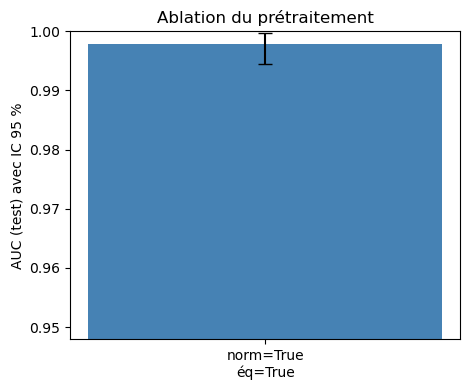

Une seule configuration archivée : lance au moins une autre configuration pour comparer.


In [27]:
import glob

rows = []
for fichier in sorted(glob.glob("results_norm_*_eqres_*.json")):
    with open(fichier, "r", encoding="utf-8") as f:
        data = json.load(f)
    prep = data.get("pretraitement", {})
    test = data["test"]
    ctrl = data.get("controles", {})
    lo, hi = test["auc"]["ic95"]
    rows.append({
        "normalisation": prep.get("normalize_intensity"),      # clés en minuscules dans model_card.json
        "égalisation": prep.get("equalize_resolution"),
        "seuil (val)": data.get("seuil"),
        "AUC test": test["auc"]["valeur"],
        "IC95 AUC": f"[{lo:.3f} ; {hi:.3f}]",
        "rappel test": test["recall"]["valeur"],
        "précision test": test["precision"]["valeur"],
        "F1 test": test["f1"]["valeur"],
        "AUC métadonnées seules": ctrl.get("auc_test_metadonnees_seules"),
        "_lo": lo, "_hi": hi, "fichier": fichier,
    })

if not rows:
    print("Aucun fichier results_norm_*_eqres_*.json : lance d'abord la cellule d'archivage.")
else:
    comp = pd.DataFrame(rows)
    display(comp.drop(columns=["_lo", "_hi", "fichier"]))

    labels = [f"norm={r['normalisation']}\néq={r['égalisation']}" for _, r in comp.iterrows()]
    auc_values = comp["AUC test"].values
    yerr = np.array([auc_values - comp["_lo"].values, comp["_hi"].values - auc_values])
    plt.figure(figsize=(1.8 * len(comp) + 3, 4))
    plt.bar(labels, auc_values, yerr=yerr, capsize=5, color="steelblue")
    plt.ylim(max(0.5, auc_values.min() - 0.05), 1.0); plt.ylabel("AUC (test) avec IC 95 %")
    plt.title("Ablation du prétraitement"); plt.tight_layout(); plt.show()

    ref = comp[(comp["normalisation"] == True) & (comp["égalisation"] == True)]
    if len(comp) < 2:
        print("Une seule configuration archivée : lance au moins une autre configuration pour comparer.")
    elif ref.empty:
        print("La configuration de référence (normalisation=True, égalisation=True) n'est pas archivée.")
    else:
        r = ref.iloc[0]
        print("Écart d'AUC par rapport à la référence (config - référence) :")
        for idx, row in comp.iterrows():
            if idx == ref.index[0]:
                continue
            delta = row["AUC test"] - r["AUC test"]
            overlap = not (row["_hi"] < r["_lo"] or row["_lo"] > r["_hi"])
            verdict = "IC qui se chevauchent : différence non significative" if overlap else "IC disjoints : différence nette"
            print(f"  norm={row['normalisation']}, éq={row['égalisation']} : ΔAUC = {delta:+.3f} ({verdict})")
        print("Lecture : un ΔAUC nettement positif quand on DÉSACTIVE une neutralisation indique que le réseau profite de cet indice ;")
        print("un ΔAUC proche de 0 indique qu'il n'en dépend pas.")

## 18. Synthèse et limites

**Ce que ce notebook permet d'affirmer** (si les contrôles ci-dessus sont satisfaisants) :
- les images de test n'ont aucune famille de quasi-doublons en commun avec le train ;
- les prédictions confiantes se concentrent sur les lésions (Grad-CAM) ;
- les scores sont donnés avec des intervalles de confiance calculés **par familles d'images**.

**Limites à garder en tête :**
- le jeu contient **beaucoup de quasi-doublons** : le nombre d'images réellement distinctes est de l'ordre de la centaine de familles par ensemble de validation/test, donc les intervalles sont larges ;
- la source des images n'est pas homogène (rapports hauteur/largeur et tailles différents selon la classe) : seul un **test sur un jeu d'une autre source** prouve la généralisation ;
- le seuil a été choisi sur une petite validation : il est instable ;
- c'est un **prototype de recherche**, pas un outil de diagnostic.

In [28]:
print("=== SYNTHÈSE ===")
print(f"Images : {len(df)} | familles distinctes ≈ {df['group'].nunique()} | seuil de regroupement : {HAMMING_MAX} bits")
for s_ in ("train", "val", "test"):
    sub = df[df["split"] == s_]
    print(f"  {s_:5s}: {len(sub):4d} images, {sub['group'].nunique():3d} familles")
print("Contrôles anti-raccourci :")
print(f"  métadonnées seules (CV groupée)               : {all_score:.1%}")
print(f"  indices de qualité d'image seuls (CV groupée) : {pix_score:.1%}")
print(f"  AUC test, métadonnées seules / réseau         : {meta_auc:.3f} / {cnn_auc:.3f}")
print(f"Test (seuil {threshold:.2f}) :")
for k in ("auc", "recall", "precision", "f1"):
    print(f"  {k:9s}: {test_m[k]:.3f}  IC 95 % [{ci[k][0]:.3f} ; {ci[k][1]:.3f}]")

=== SYNTHÈSE ===
Images : 2998 | familles distinctes ≈ 514 | seuil de regroupement : 30 bits
  train: 2075 images, 362 familles
  val  :  427 images,  77 familles
  test :  496 images,  75 familles
Contrôles anti-raccourci :
  métadonnées seules (CV groupée)               : 88.1%
  indices de qualité d'image seuls (CV groupée) : 87.7%
  AUC test, métadonnées seules / réseau         : 0.927 / 0.998
Test (seuil 0.07) :
  auc      : 0.998  IC 95 % [0.994 ; 1.000]
  recall   : 0.996  IC 95 % [0.985 ; 1.000]
  precision: 0.902  IC 95 % [0.799 ; 0.978]
  f1       : 0.947  IC 95 % [0.887 ; 0.987]


## Suite possible

1. **Test externe** : évaluer le modèle sur des IRM d'une **autre source** (un autre jeu public). C'est le seul test qui prouve que le modèle ne s'appuie pas sur les particularités de ce jeu.
2. **Validation croisée par groupes** (5 plis) pour stabiliser les chiffres et choisir le seuil sur des prédictions hors-pli.
3. **Application Streamlit** avec `predict_image()` et l'affichage Grad-CAM.

In [43]:
# Exemple d'organisation attendue :
# external_dataset/
#   no/   image_001.jpg ...
#   yes/  image_002.jpg ...
EXTERNAL_DATA_DIR = Path("external_dataset")  # À MODIFIER : dossier du jeu public indépendant

if not EXTERNAL_DATA_DIR.exists():
    print(f"Test externe non exécuté : dossier absent ({EXTERNAL_DATA_DIR.resolve()}).")
    print("Placez le jeu indépendant dans ce dossier avec les sous-dossiers no/ et yes/, puis relancez cette cellule.")
else:
    external_ds = datasets.ImageFolder(EXTERNAL_DATA_DIR, transform=eval_tf)
    if external_ds.class_to_idx != {"no": 0, "yes": 1}:
        raise ValueError(
            f"Classes externes incorrectes : {external_ds.class_to_idx}. "
            "Les dossiers doivent être nommés exactement 'no' et 'yes'."
        )
    if len(external_ds) == 0 or len(set(external_ds.targets)) < 2:
        raise ValueError("Le jeu externe doit contenir des images des deux classes.")

    external_loader = DataLoader(external_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    external_loss, external_y, external_p = run_epoch(external_loader)
    external_pred = (external_p >= threshold_oof).astype(int)
    external_metrics = compute_metrics(external_y, external_p, threshold_oof)
    print("SOURCE EXTERNE :", EXTERNAL_DATA_DIR.resolve())
    print("Nombre d'images :", len(external_ds), "| seuil OOF fixé avant test :", round(threshold_oof, 3))
    print("Métriques externes :", {k: round(v, 4) for k, v in external_metrics.items()})
    print(classification_report(external_y, external_pred, target_names=["no", "yes"], zero_division=0))
    ext_cm = confusion_matrix(external_y, external_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(ext_cm, cmap="Blues")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["no", "yes"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["no", "yes"])
    for r in range(2):
        for c in range(2): ax.text(c, r, ext_cm[r, c], ha="center", va="center")
    ax.set_xlabel("Prédit"); ax.set_ylabel("Réel"); ax.set_title("Matrice de confusion – test externe")
    plt.tight_layout(); plt.show()

    external_report = {
        "source": str(EXTERNAL_DATA_DIR.resolve()),
        "n_images": len(external_ds),
        "threshold_oof": float(threshold_oof),
        "metrics": {k: float(v) for k, v in external_metrics.items()},
        "warning": "Évaluation externe uniquement si la source est indépendante du jeu d'entraînement."
    }
    with open("external_test_report.json", "w", encoding="utf-8") as f:
        json.dump(external_report, f, ensure_ascii=False, indent=2)
    print("Rapport sauvegardé : external_test_report.json")


Test externe non exécuté : dossier absent (C:\Users\Mahamadou\Documents\DL\Tumeur\external_dataset).
Placez le jeu indépendant dans ce dossier avec les sous-dossiers no/ et yes/, puis relancez cette cellule.


In [44]:
%%writefile app_streamlit.py
# -*- coding: utf-8 -*-
"""
Application Streamlit : détection de tumeur sur IRM cérébrale (PROTOTYPE DE RECHERCHE).

Fichiers nécessaires dans le même dossier :
    app_streamlit.py   (ce fichier)
    effnet_b0_best.pt  (modèle sauvegardé par le notebook, section 11)

Installation (une seule fois) :
    python -m pip install streamlit torch torchvision pillow matplotlib

Lancement :
    python -m streamlit run app_streamlit.py

Le prétraitement ci-dessous reprend EXACTEMENT celui du notebook (recadrage, normalisation d'intensité,
égalisation de résolution, remplissage noir 224x224). Les réglages sont lus dans le fichier du modèle.
"""
import os
from pathlib import Path

import numpy as np
from PIL import Image, ImageOps
import streamlit as st
from streamlit.runtime.scriptrunner import get_script_run_ctx
import torch
from torchvision import models, transforms as T

try:
    from matplotlib import colormaps
    _JET = colormaps["jet"]
except Exception:                                   # anciennes versions de matplotlib
    import matplotlib.pyplot as plt
    _JET = plt.get_cmap("jet")

CROP_THRESHOLD = 20                                 # identique au notebook
DEFAULT_MODEL_PATH = os.environ.get("MODEL_PATH", "effnet_b0_best.pt")


# ----------------------------------------------------------------------------------------------
# Prétraitement (copie du notebook)
# ----------------------------------------------------------------------------------------------
def crop_foreground(img, thresh=CROP_THRESHOLD, margin=0.02, min_count=3):
    g = np.asarray(img.convert("L"))
    h, w = g.shape
    border = np.concatenate([g[0], g[-1], g[:, 0], g[:, -1]])
    if np.median(border) > 60:                          # fond clair : on ne recadre pas
        return img
    mask = g > thresh
    rows = np.where(mask.sum(axis=1) >= min_count)[0]
    cols = np.where(mask.sum(axis=0) >= min_count)[0]
    if len(rows) == 0 or len(cols) == 0:
        return img
    top, bottom, left, right = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
    if (bottom - top) * (right - left) < 0.2 * h * w:   # zone minuscule : on ne recadre pas
        return img
    mh, mw = int(margin * h), int(margin * w)
    return img.crop((max(0, left - mw), max(0, top - mh), min(w, right + mw), min(h, bottom + mh)))


def normalize_intensity(img, low=1.0, high=99.5):
    g = np.asarray(img.convert("L"), dtype=np.float32)
    tissue = g[g > CROP_THRESHOLD]
    if tissue.size < 100:
        return img
    lo, hi = np.percentile(tissue, [low, high])
    if hi - lo < 10:
        return img
    out = np.clip((g - lo) / (hi - lo), 0.0, 1.0) * 255.0
    return Image.fromarray(out.astype(np.uint8)).convert("RGB")


def equalize_resolution(img, common):
    w, h = img.size
    longest = max(w, h)
    if longest <= common:
        return img
    scale = common / longest
    return img.resize((max(1, round(w * scale)), max(1, round(h * scale))), Image.LANCZOS)


def prepare_pil(img, size, settings):
    """Même enchaînement que prepare_image() du notebook, mais à partir d'une image PIL."""
    img = ImageOps.exif_transpose(img).convert("RGB")
    if settings.get("crop", True):
        img = crop_foreground(img)
    if settings.get("normalize_intensity", True):
        img = normalize_intensity(img)
    if settings.get("equalize_resolution", True):
        img = equalize_resolution(img, settings.get("common_res", 160))
    return ImageOps.pad(img, (size, size), method=Image.BICUBIC, color=(0, 0, 0), centering=(0.5, 0.5))


def overlay_cam(rgb_array, cam, alpha=0.4):
    """Superpose la carte de chaleur (valeurs 0-1) à l'image RGB (uint8)."""
    heat = _JET(cam)[..., :3]
    mixed = (1 - alpha) * (rgb_array.astype(np.float32) / 255.0) + alpha * heat
    return (np.clip(mixed, 0, 1) * 255).astype(np.uint8)


# ----------------------------------------------------------------------------------------------
# Modèle
# ----------------------------------------------------------------------------------------------
@st.cache_resource(show_spinner="Chargement du modèle...")
def load_model(path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(path, map_location=device)
    net = models.efficientnet_b0(weights=None)
    net.classifier[1] = torch.nn.Linear(net.classifier[1].in_features, 1)
    net.load_state_dict(checkpoint["state_dict"])
    net.to(device).eval()
    return net, checkpoint, device


def predict_with_cam(net, tensor, device, size):
    """Probabilité de tumeur + carte Grad-CAM (valeurs 0-1, taille size x size)."""
    x = tensor.unsqueeze(0).to(device).clone().detach().requires_grad_(True)
    with torch.enable_grad():
        feats = net.features(x)                                       # (1, 1280, 7, 7)
        logit = net.classifier(torch.flatten(net.avgpool(feats), 1))
        grads = torch.autograd.grad(logit.sum(), feats)[0]
    weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((weights * feats).sum(dim=1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=(size, size), mode="bilinear", align_corners=False)[0, 0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return torch.sigmoid(logit).item(), cam.detach().cpu().numpy()


# ----------------------------------------------------------------------------------------------
# Interface
# ----------------------------------------------------------------------------------------------
def main():
    st.set_page_config(page_title="IRM cérébrale – prototype", page_icon="🧠", layout="wide")
    st.title("🧠 Détection de tumeur sur IRM cérébrale")
    st.warning(
        "**Prototype de recherche.** Ce modèle a été entraîné sur un jeu public contenant beaucoup d'images quasi "
        "identiques. Il ne remplace pas un avis médical et ne doit **jamais** servir à un diagnostic."
    )

    with st.sidebar:
        st.header("Réglages")
        model_path = st.text_input("Fichier du modèle", DEFAULT_MODEL_PATH)
        show_cam = st.checkbox("Afficher le Grad-CAM", value=True)

    if not Path(model_path).exists():
        st.error(f"Modèle introuvable : `{model_path}`. Place `effnet_b0_best.pt` dans le dossier de l'application "
                 "(ou indique le chemin dans la barre latérale).")
        st.stop()
        return

    net, checkpoint, device = load_model(model_path)
    size = int(checkpoint.get("img_size", 224))
    settings = checkpoint.get("prep_settings", {})
    default_threshold = float(checkpoint.get("threshold", 0.5))
    to_tensor = T.Compose([T.ToTensor(), T.Normalize(checkpoint["mean"], checkpoint["std"])])

    with st.sidebar:
        threshold = st.slider("Seuil de décision", 0.05, 0.95, float(np.clip(default_threshold, 0.05, 0.95)), 0.01,
                              help="Probabilité à partir de laquelle l'image est classée « tumeur ». "
                                   "Un seuil bas détecte plus de tumeurs mais génère plus de fausses alertes.")
        st.caption(f"Seuil enregistré avec le modèle : {default_threshold:.2f} | appareil : {device}")

    uploaded = st.file_uploader("Choisissez une IRM cérébrale (JPG ou PNG)", type=["jpg", "jpeg", "png"])
    if uploaded is None:
        st.info("Envoyez une image pour lancer l'analyse.")
        st.stop()
        return

    try:
        original = Image.open(uploaded)
        original.load()
        prepared = prepare_pil(original, size, settings)
    except Exception as error:
        st.error(f"Impossible de lire cette image : {error}")
        st.stop()
        return

    prob, cam = predict_with_cam(net, to_tensor(prepared), device, size)
    predicted_tumor = prob >= threshold

    left, middle, right = st.columns(3)
    with left:
        st.subheader("Image envoyée")
        st.image(original.convert("RGB"), width=320)
    with middle:
        st.subheader("Image prétraitée")
        st.image(prepared, width=320)
    with right:
        st.subheader("Grad-CAM" if show_cam else "")
        if show_cam:
            st.image(overlay_cam(np.asarray(prepared), cam), width=320)
            st.caption("Zones qui ont le plus poussé le modèle vers « tumeur ». Ce n'est pas une segmentation : "
                       "la carte ne localise pas forcément la lésion.")

    st.divider()
    st.metric("Probabilité de tumeur", f"{prob:.1%}")
    st.progress(float(np.clip(prob, 0.0, 1.0)))
    if predicted_tumor:
        st.error(f"Le modèle classe cette image comme **tumeur probable** (probabilité {prob:.1%} ≥ seuil {threshold:.2f}).")
    else:
        st.success(f"Le modèle classe cette image comme **sans tumeur** (probabilité {prob:.1%} < seuil {threshold:.2f}).")
    if abs(prob - threshold) < 0.15:
        st.warning("Le résultat est **proche du seuil** : il est incertain.")

    with st.expander("À propos du modèle et de ses limites"):
        st.markdown(
            f"""
- Modèle : EfficientNet-B0 pré-entraîné (ImageNet), sortie binaire, image d'entrée {size} × {size}.
- Prétraitement : recadrage = {settings.get('crop')}, normalisation d'intensité = {settings.get('normalize_intensity')},
  égalisation de résolution = {settings.get('equalize_resolution')} (côté max {settings.get('common_res')} px).
- Les scores affichés dans le notebook viennent d'un jeu public à fort taux de quasi-doublons (nombre réel d'images
  distinctes bien plus faible que le nombre d'images). Seul un test sur un jeu d'une **autre source** prouve la
  généralisation.
- Les images hors IRM cérébrales axiales, très différentes du jeu d'entraînement (autres séquences, autres
  plans de coupe, captures d'écran...) donnent des résultats **non fiables**.
"""
        )


if __name__ == "__main__" and get_script_run_ctx() is not None:
    main()


Overwriting app_streamlit.py


In [45]:
import subprocess, sys, time
from pathlib import Path

if not Path("app_streamlit.py").exists():
    raise FileNotFoundError("Exécutez d'abord la cellule qui génère app_streamlit.py.")
if not Path("effnet_b0_best.pt").exists():
    raise FileNotFoundError("Checkpoint effnet_b0_best.pt absent : exécutez d'abord l'entraînement et la sauvegarde.")
streamlit_process = subprocess.Popen(
    [sys.executable, "-m", "streamlit", "run", "app_streamlit.py", "--server.headless", "true"],
    stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT
)
time.sleep(3)
print("Streamlit lancé. Ouvrez : http://localhost:8501")
print("PID :", streamlit_process.pid)

Streamlit lancé. Ouvrez : http://localhost:8501
PID : 8240
